<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values per column (before dropna):
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Missing values per column (after dropna):
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64
Rows before: 344 | Rows after: 342

Means after scaling:
bill_length_mm       0.0
bill_depth_mm       -0.0
flipper_length_mm   -0.0
body_mass_g          0.0
dtype: float64
Stds after scaling:
bill_length_mm       1.001
bill_depth_mm        1.001
flipper_length_mm    1.001
body_mass_g          1.001
dtype: float64

First 20 k-means labels: [1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 2 1 2 1]


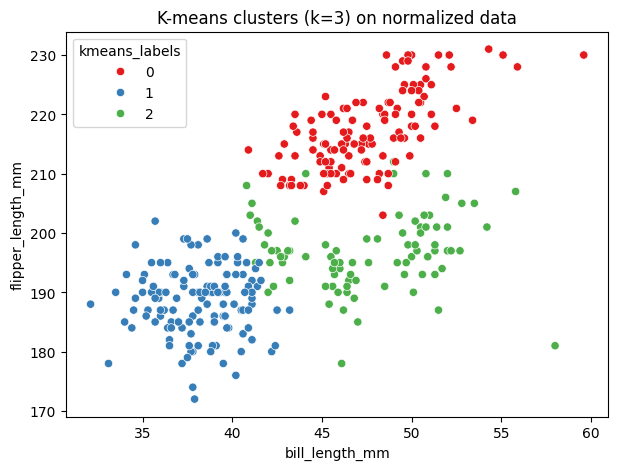

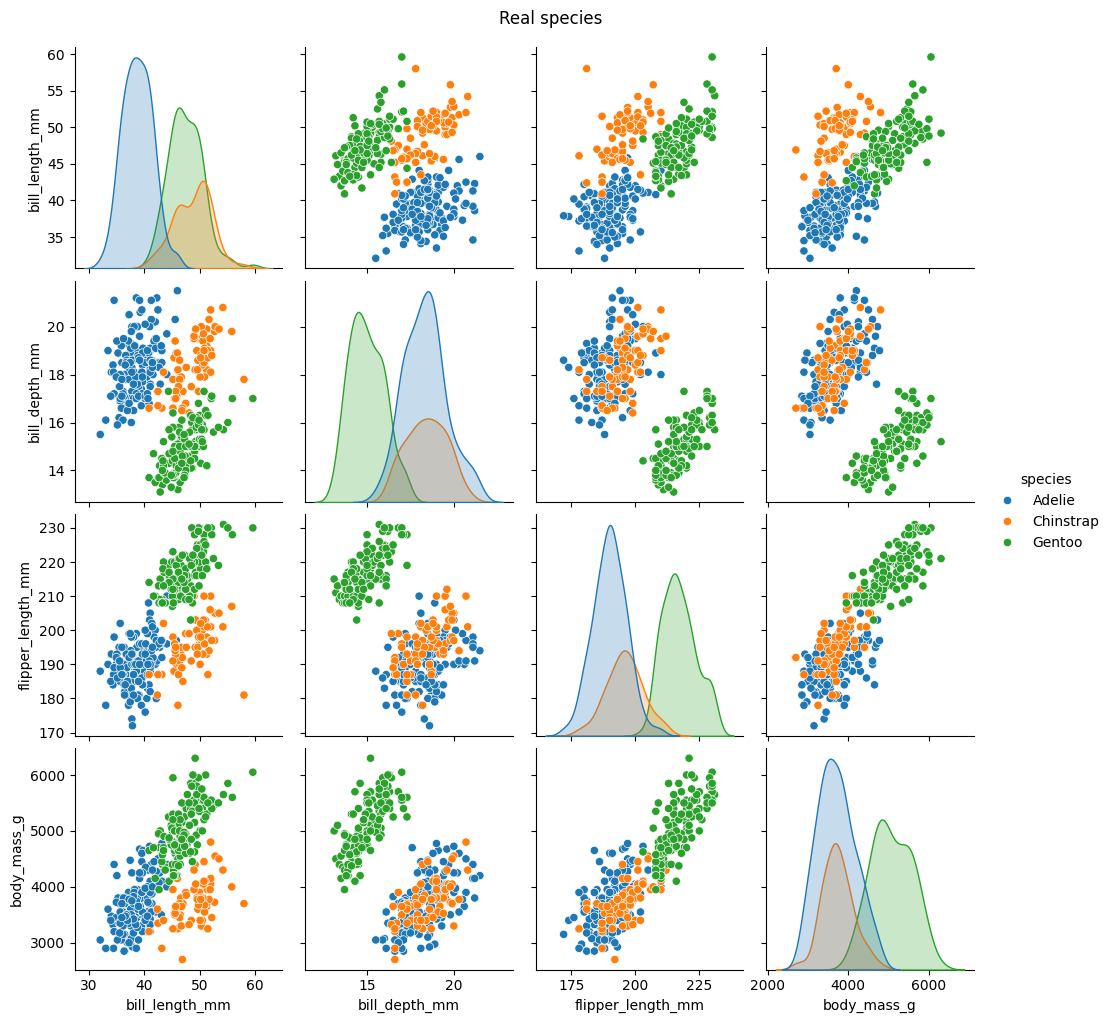

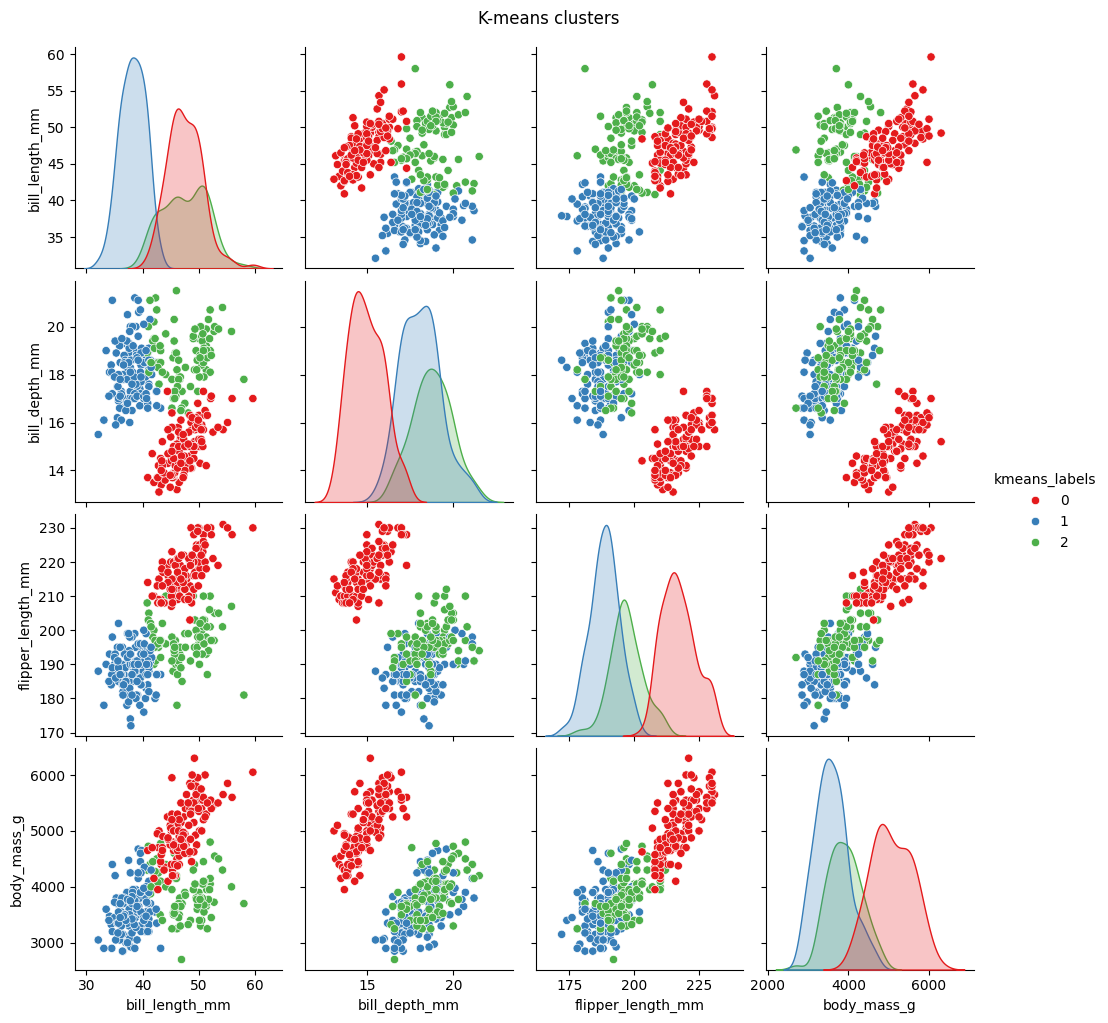

Species encoding: ['Adelie', 'Chinstrap', 'Gentoo'] -> 0, 1, 2

Confusion matrix (rows = real species, columns = k-means cluster):
[[  0 127  24]
 [  0   5  63]
 [123   0   0]]


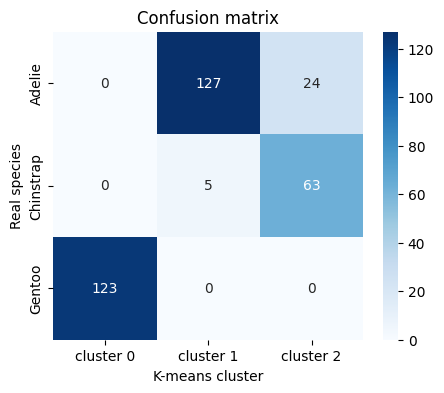

Adjusted Rand score (normalized data): 0.793

Confusion matrix with RAW data:
[[  0 116  35]
 [  0  53  15]
 [ 68   1  54]]
Adjusted Rand score (raw data): 0.331


In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
print("Missing values per column (before dropna):")
print(penguins[num_cols].isna().sum())

# I also keep the 'species' column (not used for clustering, only to compare in d) and e))
penguins_clean = penguins[num_cols + ['species']].dropna()
penguins_clean = penguins_clean.reset_index(drop=True)  # renumber rows 0,1,2,...

print("\nMissing values per column (after dropna):")
print(penguins_clean.isna().sum())
print("Rows before:", len(penguins), "| Rows after:", len(penguins_clean))

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
scaler = StandardScaler()
penguins_scaled = scaler.fit_transform(penguins_clean[num_cols])
penguins_scaled_df = pd.DataFrame(penguins_scaled, columns=num_cols)

# check: every column should now have mean ~0 and std ~1
print("\nMeans after scaling:")
print(penguins_scaled_df.mean().round(3))
print("Stds after scaling:")
print(penguins_scaled_df.std().round(3))

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
kmeans.fit(penguins_scaled_df)
kmeans_labels = kmeans.labels_
print("\nFirst 20 k-means labels:", kmeans_labels[:20])

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
penguins_clean['kmeans_labels'] = kmeans_labels

plt.figure(figsize=(7, 5))
sns.scatterplot(data=penguins_clean, x='bill_length_mm', y='flipper_length_mm',
                hue='kmeans_labels', palette='Set1')
plt.title('K-means clusters (k=3) on normalized data')
plt.show()

# pairplot colored by the REAL species
sns.pairplot(penguins_clean, vars=num_cols, hue='species')
plt.suptitle('Real species', y=1.02)
plt.show()

# pairplot colored by the k-means clusters
sns.pairplot(penguins_clean, vars=num_cols, hue='kmeans_labels', palette='Set1')
plt.suptitle('K-means clusters', y=1.02)
plt.show()

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
#confusion_matrix doesn't like mixing text labels and numbers, so I turn species into numbers first
le = LabelEncoder()
species_num = le.fit_transform(penguins_clean['species'])
print("Species encoding:", list(le.classes_), "-> 0, 1, 2")

cm = confusion_matrix(species_num, kmeans_labels)
print("\nConfusion matrix (rows = real species, columns = k-means cluster):")
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            yticklabels=le.classes_, xticklabels=['cluster 0', 'cluster 1', 'cluster 2'])
plt.ylabel('Real species')
plt.xlabel('K-means cluster')
plt.title('Confusion matrix')
plt.show()

ari = adjusted_rand_score(species_num, kmeans_labels)
print("Adjusted Rand score (normalized data):", round(ari, 3))

# extra for f): same k-means but on the RAW (not normalized) values, to compare
kmeans_raw = KMeans(n_clusters=3, random_state=0, n_init=10)
raw_labels = kmeans_raw.fit_predict(penguins_clean[num_cols])
print("\nConfusion matrix with RAW data:")
print(confusion_matrix(species_num, raw_labels))
ari_raw = adjusted_rand_score(species_num, raw_labels)
print("Adjusted Rand score (raw data):", round(ari_raw, 3))

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation
# - Yes, k-means recovers the species quite well on the normalized data: adjusted Rand score
#   is about 0.79 (1 = perfect match with the species, 0 = no better than random).
# - Gentoo is found perfectly: all 123 Gentoo penguins end up alone in their own cluster.
#   Makes sense, in the pairplot they are clearly separated (long flippers, heavy, shallow bill).
# - The mistakes are between Adelie and Chinstrap: in my run 24 Adelie were put in the
#   "Chinstrap" cluster and 5 Chinstrap in the "Adelie" cluster. These two species have very
#   similar body mass, flipper length and bill depth, they mainly differ in bill length,
#   so they overlap and k-means can't fully separate them.
# - Normalizing changed the result a lot: with the raw values the ARI drops to about 0.33.
#   Without scaling, body_mass_g (thousands of grams) dominates the Euclidean distance, so
#   k-means basically splits the penguins by weight only (it even splits Gentoo in two)
#   and ignores the bill measurements.

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Any missing values in X? False
X scaled:
[[-1.    -0.234]
 [-1.     0.701]
 [-1.    -1.168]
 [ 1.     1.635]
 [ 1.     0.234]
 [ 1.    -1.168]]
5.656854249492381
5.656854249492381


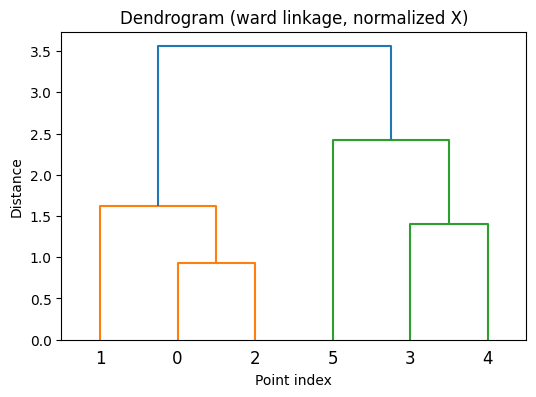

[1 1 1 0 0 0]
[0 0 0 1 1 1]


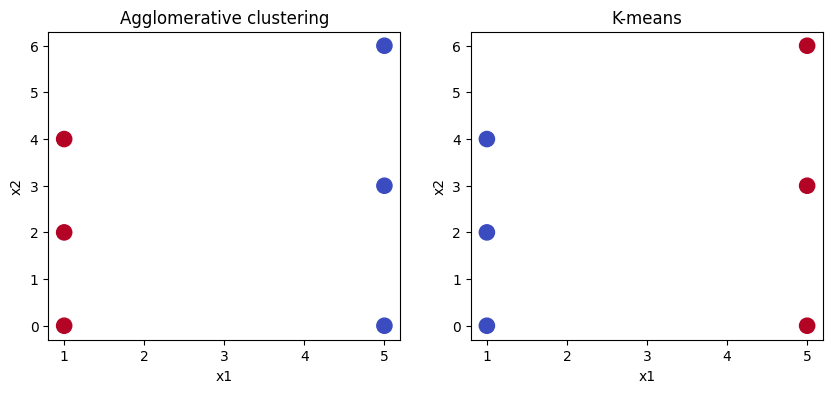

Same labels: False | Same groups but labels swapped: True
{1: 3, 0: 3}
{0: 3, 1: 3}


In [3]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
print("Any missing values in X?", np.isnan(X).any())  # False means no NaN, we're good

# b) YOUR CODE HERE: normalize X with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("X scaled:")
print(X_scaled.round(3))

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    total = 0
    for i in range(len(p1)):
        diff = p1[i] - p2[i]
        total = total + diff ** 2
    return total ** 0.5

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)

Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(6, 4))
dendrogram(Z)
plt.title('Dendrogram (ward linkage, normalized X)')
plt.xlabel('Point index')
plt.ylabel('Distance')
plt.show()

# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print(agglo_labels)
print(kmeans_labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap='coolwarm', s=120)
axes[0].set_title('Agglomerative clustering')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='coolwarm', s=120)
axes[1].set_title('K-means')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')
plt.show()

# the numbers 0/1 are just names, so the two methods could give the same groups with the
# labels swapped. To check if the GROUPS are the same I compare both ways:
same = True
same_swapped = True
for i in range(len(agglo_labels)):
    if agglo_labels[i] != kmeans_labels[i]:
        same = False
    if agglo_labels[i] == kmeans_labels[i]:
        same_swapped = False
print("Same labels:", same, "| Same groups but labels swapped:", same_swapped)
# Answer: both methods find exactly the same 2 groups, the 3 points with x=1 (left) and the
# 3 points with x=5 (right). Only the numbers are swapped (agglomerative calls the left group 1,
# k-means calls it 0), which doesn't matter because cluster numbers are arbitrary names.
# The dendrogram agrees: the biggest jump in height is the very last merge, where the
# left group {0,1,2} and the right group {3,4,5} get joined, so cutting there gives 2 clusters.

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        label = int(label)   # numpy int -> normal int so the dict prints nicely
        if label in counts:
            counts[label] = counts[label] + 1
        else:
            counts[label] = 1
    return counts

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values before dropna:
carat    0
depth    0
table    0
price    0
dtype: int64
Total missing values after dropna: 0
Rows: 1000
Mean price: 4165.1 | Std price: 4190.1


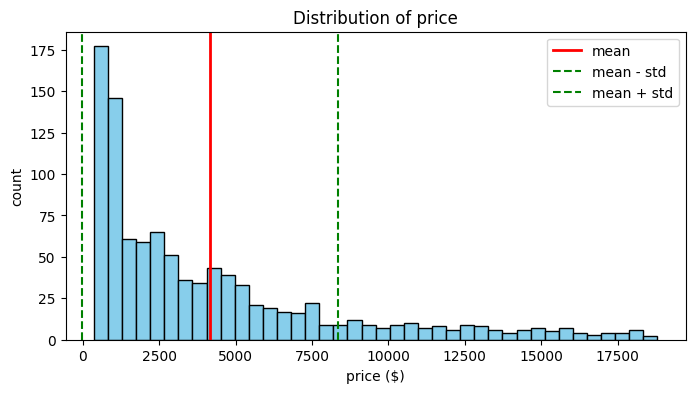

n = 1  BIC = 9270.1
n = 2  BIC = 7589.3
n = 3  BIC = 7125.4
n = 4  BIC = 6976.9
n = 5  BIC = 6952.4
n = 6  BIC = 6854.1
n = 7  BIC = 6835.8
n = 8  BIC = 6924.0


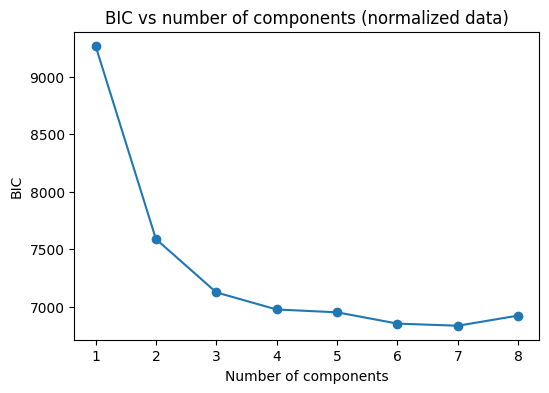

Best number of components: 7


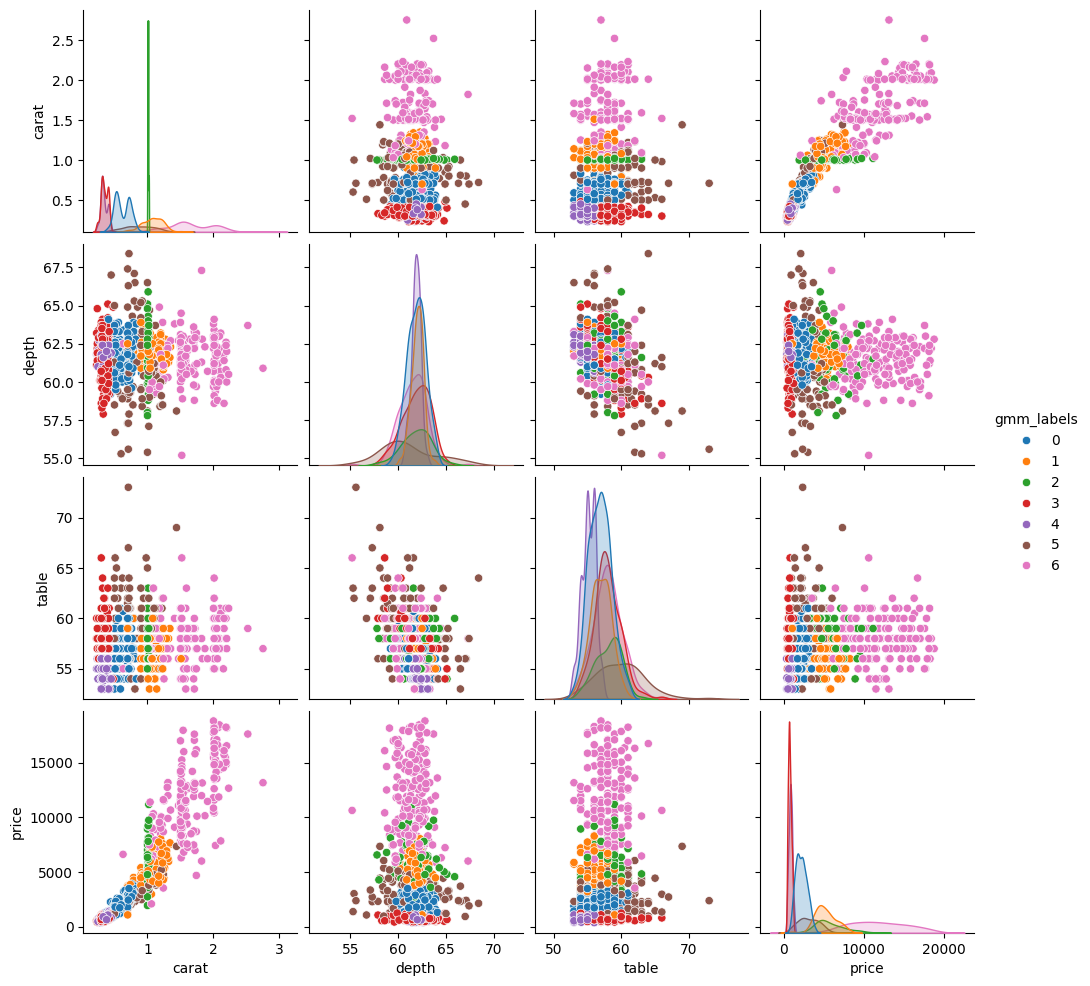

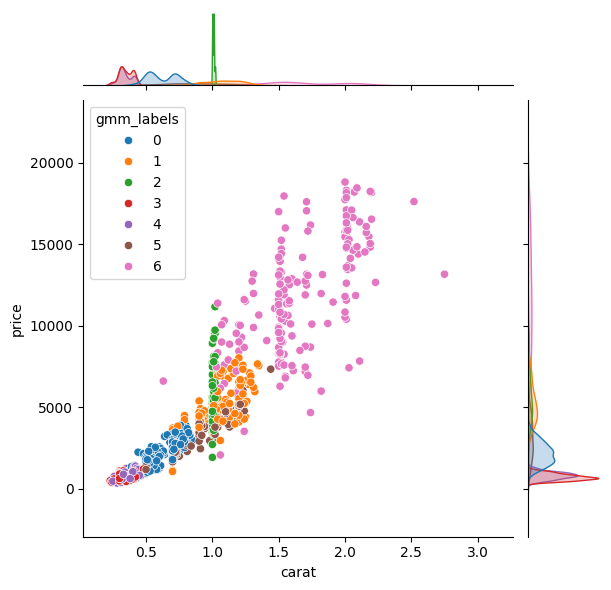

Best number of components with RAW data: 5


In [4]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']].copy()
print("Missing values before dropna:")
print(diamonds_num.isna().sum())

diamonds_num = diamonds_num.dropna()
print("Total missing values after dropna:", diamonds_num.isna().sum().sum())
print("Rows:", len(diamonds_num))

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()
print("Mean price:", round(mean_price, 1), "| Std price:", round(std_price, 1))

plt.figure(figsize=(8, 4))
plt.hist(diamonds_num['price'], bins=40, color='skyblue', edgecolor='black')
plt.axvline(mean_price, color='red', linewidth=2, label='mean')
plt.axvline(mean_price - std_price, color='green', linestyle='--', label='mean - std')
plt.axvline(mean_price + std_price, color='green', linestyle='--', label='mean + std')
plt.xlabel('price ($)')
plt.ylabel('count')
plt.title('Distribution of price')
plt.legend()
plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

# n_init=5: try 5 different starting points and keep the best one. Without it the BIC values
# jumped around between runs and the "best" n kept changing (4, 7, 8...)
for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n, covariance_type='full', random_state=0, n_init=5)
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))
    print("n =", n, " BIC =", round(bic[-1], 1))

plt.figure(figsize=(6, 4))
plt.plot(list(n_components_range), bic, marker='o')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.title('BIC vs number of components (normalized data)')
plt.show()

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n = bic.index(min(bic)) + 1   # +1 because the list starts at n=1 but indexes start at 0
print("Best number of components:", best_n)

gmm_final = mixture.GaussianMixture(n_components=best_n, covariance_type='full', random_state=0, n_init=5)
gmm_final.fit(diamonds_scaled)
gmm_labels = gmm_final.predict(diamonds_scaled)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num['gmm_labels'] = gmm_labels

sns.pairplot(diamonds_num, vars=['carat', 'depth', 'table', 'price'], hue='gmm_labels', palette='tab10')
plt.show()

sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_labels', palette='tab10')
plt.show()

# extra for g): same BIC loop but on the RAW values (not normalized), to compare
raw_data = diamonds_num[['carat', 'depth', 'table', 'price']]   # without the label column
bic_raw = []
for n in n_components_range:
    gmm_raw = mixture.GaussianMixture(n_components=n, covariance_type='full', random_state=0, n_init=5)
    gmm_raw.fit(raw_data)
    bic_raw.append(gmm_raw.bic(raw_data))

best_n_raw = bic_raw.index(min(bic_raw)) + 1
print("Best number of components with RAW data:", best_n_raw)

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
# - The BIC drops a lot from 1 to 4 components and after that the curve is almost flat.
#   The minimum is at 7 components, but 4 to 8 are all pretty close, so BIC is really saying
#   "at least 4, and a few more is slightly better", not one super obvious answer.
# - In the pairplot/jointplot the clusters are mostly price/size levels along the carat-price
#   curve (small cheap stones, medium ones, big expensive ones), plus some special groups:
#   one cluster is basically only the diamonds of exactly 1.00 carat (a lot of stones are cut
#   to exactly 1 carat), and another one is a wide "catch-all" cluster with unusual depth/table.
# - Just by eye I would have guessed fewer, maybe 2 or 3 (small/cheap vs big/expensive),
#   because carat vs price looks like one continuous curved cloud, not separate blobs.
#   A GMM needs several Gaussians to approximate that curved and skewed shape, that's why
#   BIC asks for more components than what we "see".
# - Normalizing did change the result: with raw values BIC picks 5 components instead of 7.
#   Interesting detail: in theory a GMM with full covariance can adapt to different scales by
#   itself, but its initialization uses k-means (Euclidean distance), so with raw data price
#   dominates the starting point and the fit ends up in a worse solution (higher BIC once you
#   correct for the units). So scaling still matters in practice.